# Trabalho de Grafos e Redes Sociais
Análise comparativa entre grafos sintéticos (ER, BA, WS) e o grafo real Facebook ego (SNAP).

As discussões e respostas estão no PDF que acompanha este notebook.

In [1]:
import os, gzip, math, urllib.request
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RNG = np.random.default_rng(42)

NetworkX: 3.6.1


In [2]:
# função geradora
def extract_metrics(G, sample_threshold=500, bet_k=200):
    if not nx.is_connected(G):
        G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    n, m = G.number_of_nodes(), G.number_of_edges()
    deg = np.array([d for _, d in G.degree()])

    out = {
        "n": n, "m": m,
        "avg_degree": deg.mean(),
        "max_degree": int(deg.max()),
        "degree_var": deg.var(),
        "density": nx.density(G),
        "clustering_global": nx.transitivity(G),
        "clustering_avg": nx.average_clustering(G),
        "assortativity": nx.degree_assortativity_coefficient(G),
    }
    if n <= sample_threshold:
        lengths = []
        for src, dists in nx.all_pairs_shortest_path_length(G):
            lengths.extend(v for v in dists.values() if v > 0)
        out["diameter"] = nx.diameter(G)
    else:
        sources = RNG.choice(list(G.nodes()), size=min(200, n), replace=False)
        lengths = []
        for s in sources:
            d_dict = nx.single_source_shortest_path_length(G, s)
            lengths.extend(v for v in d_dict.values() if v > 0)
        out["diameter"] = int(max(lengths))
    out["avg_shortest_path"] = float(np.mean(lengths))

    bet = nx.betweenness_centrality(G, k=min(bet_k, n), seed=0)
    out["max_betweenness"] = max(bet.values())
    out["max_closeness"]   = max(nx.closeness_centrality(G).values())
    out["max_pagerank"]    = max(nx.pagerank(G).values())
    return out

def run_one(model, n, seed, params):
    if model == "ER":
        G = nx.erdos_renyi_graph(n, params["p"], seed=seed)
    elif model == "BA":
        G = nx.barabasi_albert_graph(n, params["m"], seed=seed)
    elif model == "WS":
        G = nx.watts_strogatz_graph(n, params["k"], params["beta"], seed=seed)
    return {"model": model, "n": n, "seed": seed, **params, **extract_metrics(G)}

print("OK")


OK


In [3]:
# grid sintético
N_VALUES    = [100, 300, 500]
SEEDS       = [0, 1, 2]
ER_P        = [0.01, 0.05, 0.1, 0.2]
BA_M        = [1, 2, 5, 10]
WS_K        = [4, 6, 10]
WS_BETA     = [0.0, 0.01, 0.1, 0.5, 1.0]

tasks = []
for n in N_VALUES:
    for s in SEEDS:
        for p in ER_P:               tasks.append(("ER", n, s, {"p": p}))
        for m in BA_M:               tasks.append(("BA", n, s, {"m": m}))
        for k in WS_K:
            for b in WS_BETA:        tasks.append(("WS", n, s, {"k": k, "beta": b}))

print(f"Gerando {len(tasks)} grafos...")
results = [run_one(*t) for t in tqdm(tasks)]
df = pd.DataFrame(results)
df.to_csv("metricas_sinteticas.csv", index=False)
print("Shape:", df.shape)
df.head()


Gerando 207 grafos...


  0%|          | 0/207 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/networkx/algorithms/assortativity/correlation.py:302: RuntimeWarning: invalid value encountered in scalar divide
  return float((xy * (M - ab)).sum() / np.sqrt(vara * varb))


Shape: (207, 19)


,model,n,seed,p,m,avg_degree,max_degree,degree_var,density,clustering_global,clustering_avg,assortativity,diameter,avg_shortest_path,max_betweenness,max_closeness,max_pagerank,k,beta
0,ER,20,0,0.01,20,2.000000,3,0.500000,0.105263,0.120000,0.083333,-0.142857,10,4.678947,0.643275,0.316667,0.079750,NaN,NaN
1,ER,99,0,0.05,280,5.656566,12,6.205285,0.057720,0.050279,0.052557,-0.001943,6,2.803958,0.071823,0.429825,0.020094,NaN,NaN
2,ER,100,0,0.10,511,10.220000,20,8.431600,0.103232,0.100526,0.097745,0.014546,4,2.206667,0.036067,0.526596,0.017834,NaN,NaN
3,ER,100,0,0.20,974,19.480000,30,14.089600,0.196768,0.196161,0.195710,-0.019380,3,1.818788,0.019530,0.589286,0.014466,NaN,NaN
4,BA,100,0,NaN,99,1.980000,18,5.799600,0.020000,0.000000,0.000000,-0.265817,9,4.816566,0.684395,0.336735,0.078962,NaN,NaN


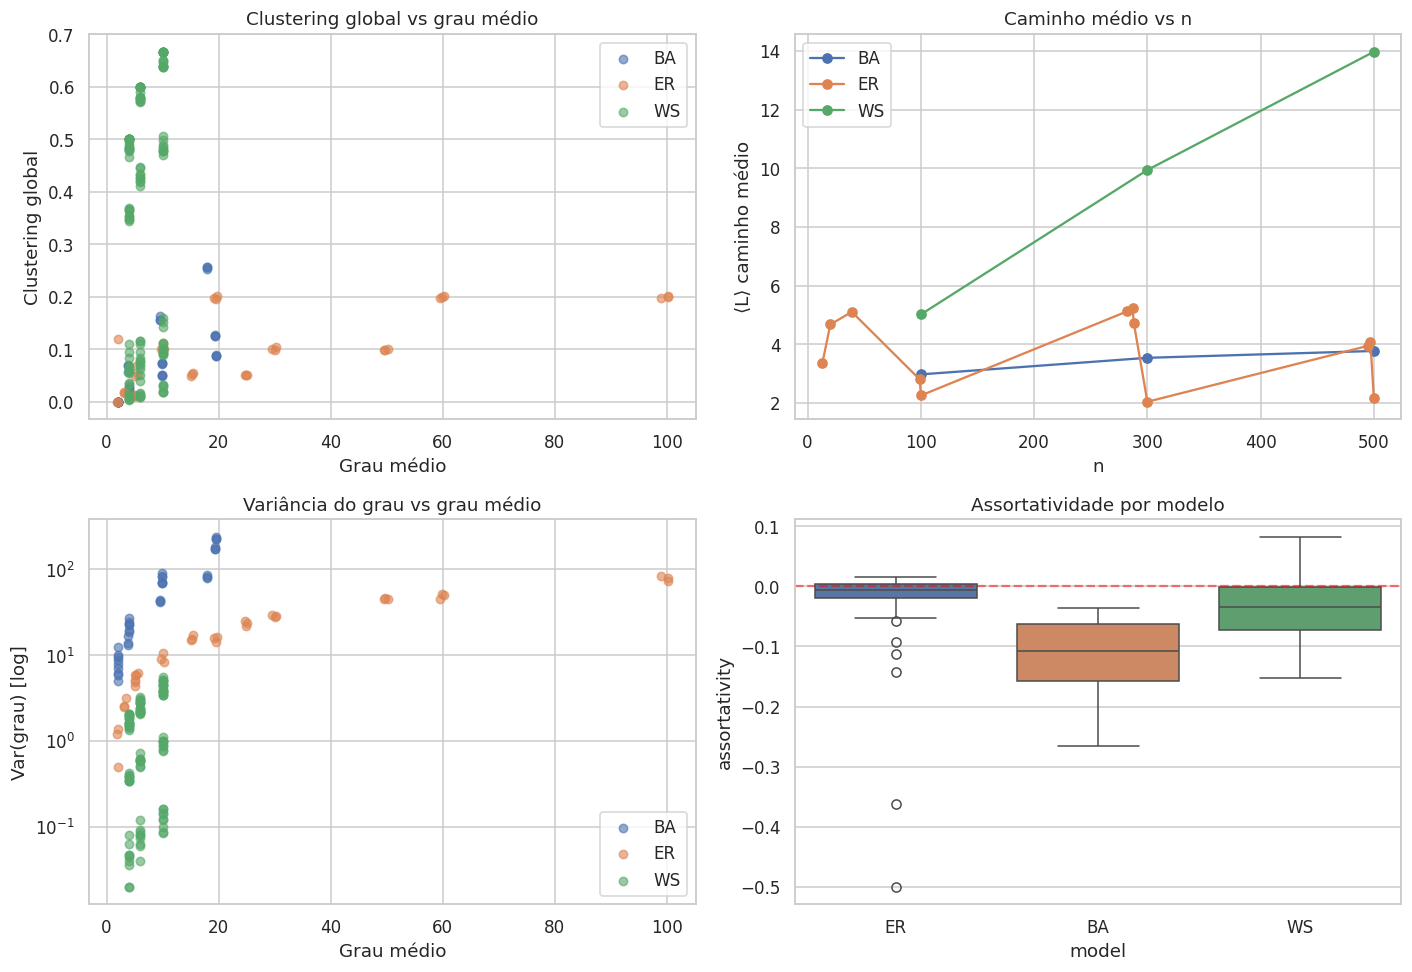

In [4]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# comparação: Clustering global vs grau médio
ax = axes[0,0]
for model, sub in df.groupby("model"):
    ax.scatter(sub["avg_degree"], sub["clustering_global"], label=model, alpha=0.6, s=30)
ax.set_xlabel("Grau médio"); ax.set_ylabel("Clustering global")
ax.set_title("Clustering global vs grau médio"); ax.legend()

# comparação: Caminho médio vs n
ax = axes[0,1]
for model, sub in df.groupby("model"):
    g = sub.groupby("n")["avg_shortest_path"].mean()
    ax.plot(g.index, g.values, "o-", label=model)
ax.set_xlabel("n"); ax.set_ylabel("⟨L⟩ caminho médio")
ax.set_title("Caminho médio vs n"); ax.legend()

# comparação: Variância do grau
ax = axes[1,0]
for model, sub in df.groupby("model"):
    ax.scatter(sub["avg_degree"], sub["degree_var"], label=model, alpha=0.6, s=30)
ax.set_yscale("log")
ax.set_xlabel("Grau médio"); ax.set_ylabel("Var(grau) [log]")
ax.set_title("Variância do grau vs grau médio"); ax.legend()

# comparação: Assortatividade por modelo
ax = axes[1,1]
sns.boxplot(data=df, x="model", y="assortativity", hue="model", legend=False, ax=ax)
ax.axhline(0, color="red", ls="--", alpha=0.5)
ax.set_title("Assortatividade por modelo")

plt.tight_layout(); plt.savefig("parte1_geral.png", dpi=130, bbox_inches="tight"); plt.show()


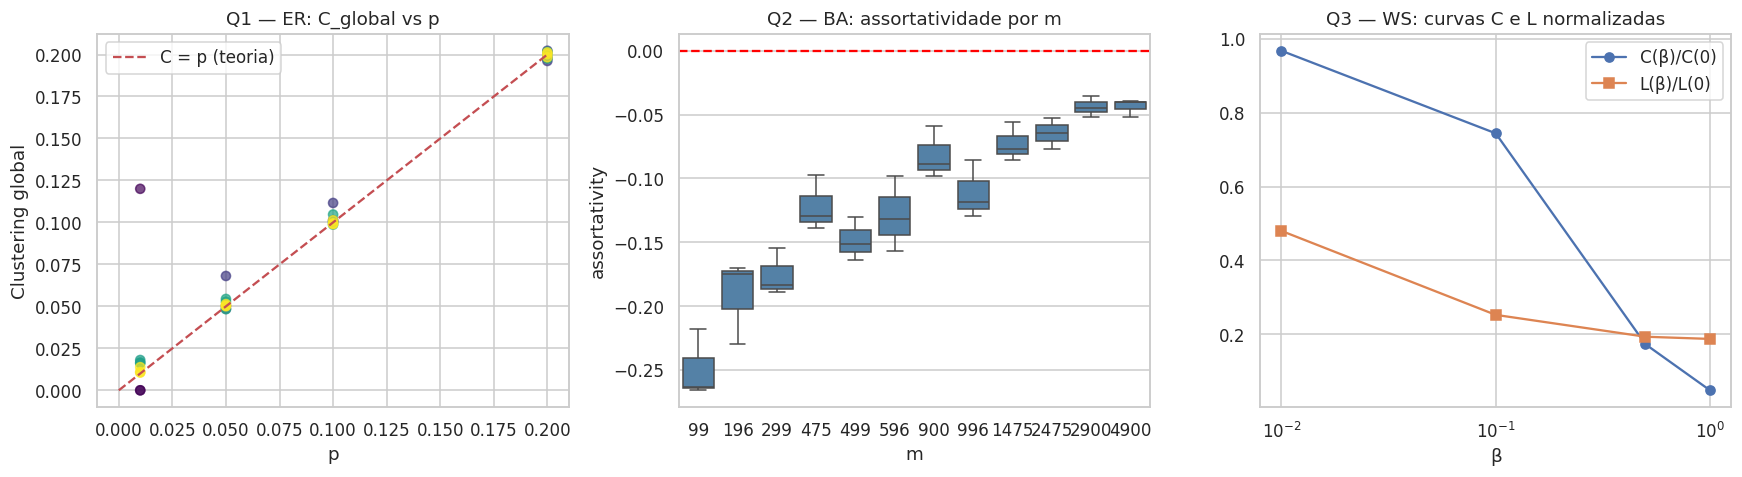


Q1 — Pearson(p, C_global) em ER: 0.9654
Q2 — Assortatividade média BA: -0.1194 (negativa → dissortativa)
Q3 — Em β=0.1: C/C0 ≈ 0.74, L/L0 ≈ 0.25


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Q1: ER -> C_global ≈ p ?
er = df[df["model"] == "ER"]
ax = axes[0]
ax.scatter(er["p"], er["clustering_global"], c=er["n"], cmap="viridis", alpha=0.7)
xs = np.linspace(0, er["p"].max(), 50)
ax.plot(xs, xs, "r--", label="C = p (teoria)")
ax.set_xlabel("p"); ax.set_ylabel("Clustering global")
ax.set_title("Q1 — ER: C_global vs p"); ax.legend()
corr_q1 = stats.pearsonr(er["p"], er["clustering_global"])[0]

# Q2: BA -> dissortativo?
ba = df[df["model"] == "BA"]
ax = axes[1]
sns.boxplot(data=ba, x="m", y="assortativity", ax=ax, color="steelblue")
ax.axhline(0, color="red", ls="--")
ax.set_title("Q2 — BA: assortatividade por m")

# Q3: WS -> curva small-world C(β)/C(0) vs L(β)/L(0)
ws = df[df["model"] == "WS"].copy()
ws_norm = []
for (n, k), g in ws.groupby(["n", "k"]):
    base = g[g["beta"] == 0.0]
    if base.empty: continue
    c0, l0 = base["clustering_avg"].mean(), base["avg_shortest_path"].mean()
    if c0 == 0 or l0 == 0: continue
    g2 = g.copy()
    g2["Cn"] = g2["clustering_avg"] / c0
    g2["Ln"] = g2["avg_shortest_path"] / l0
    ws_norm.append(g2)
ws_norm = pd.concat(ws_norm)
ax = axes[2]
agg = ws_norm[ws_norm["beta"] > 0].groupby("beta")[["Cn", "Ln"]].mean()
ax.plot(agg.index, agg["Cn"], "o-", label="C(β)/C(0)")
ax.plot(agg.index, agg["Ln"], "s-", label="L(β)/L(0)")
ax.set_xscale("log")
ax.set_xlabel("β"); ax.set_title("Q3 — WS: curvas C e L normalizadas")
ax.legend()

plt.tight_layout(); plt.savefig("parte1_questoes.png", dpi=130, bbox_inches="tight"); plt.show()

print(f"\nQ1 — Pearson(p, C_global) em ER: {corr_q1:.4f}")
print(f"Q2 — Assortatividade média BA: {ba['assortativity'].mean():.4f} (negativa → dissortativa)")
print(f"Q3 — Em β=0.1: C/C0 ≈ {agg.loc[0.1,'Cn']:.2f}, L/L0 ≈ {agg.loc[0.1,'Ln']:.2f}")


In [6]:
URL = "https://snap.stanford.edu/data/facebook_combined.txt.gz"
if not os.path.exists("fb.txt.gz"):
    urllib.request.urlretrieve(URL, "fb.txt.gz")
with gzip.open("fb.txt.gz", "rt") as f:
    G_real = nx.read_edgelist(f, nodetype=int)
print(f"Facebook real: n={G_real.number_of_nodes()}, m={G_real.number_of_edges()}")

def metrics_large(G, sample=500, bet_k=500):
    if not nx.is_connected(G):
        G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    n, m = G.number_of_nodes(), G.number_of_edges()
    deg = np.array([d for _, d in G.degree()])
    sources = RNG.choice(list(G.nodes()), size=min(sample, n), replace=False)
    lengths = []
    for s in sources:
        d_dict = nx.single_source_shortest_path_length(G, s)
        lengths.extend(v for v in d_dict.values() if v > 0)
    out = {
        "n": n, "m": m,
        "avg_degree": deg.mean(), "max_degree": int(deg.max()),
        "clustering_global": nx.transitivity(G),
        "clustering_avg": nx.average_clustering(G),
        "assortativity": nx.degree_assortativity_coefficient(G),
        "avg_shortest_path": float(np.mean(lengths)),
        "diameter": int(max(lengths)),
    }
    out["betweenness"] = nx.betweenness_centrality(G, k=min(bet_k, n), seed=0)
    out["degree_c"]    = nx.degree_centrality(G)
    out["closeness"]   = nx.closeness_centrality(G)
    out["pagerank"]    = nx.pagerank(G)
    return out, G

print("Calculando métricas do Facebook real (pode levar ~3min)...")
real_m, G_real = metrics_large(G_real)

# Paralelos sintéticos com mesmo n e k
n_r, k_r = real_m["n"], real_m["avg_degree"]
p_eq = 2 * real_m["m"] / (n_r * (n_r - 1))
m_BA = max(1, int(round(k_r / 2)))
k_WS = int(round(k_r)); k_WS = k_WS + 1 if k_WS % 2 else k_WS

print(f"\nGerando paralelos: ER(p={p_eq:.4f}), BA(m={m_BA}), WS(k={k_WS}, β=0.1)")
G_er = nx.erdos_renyi_graph(n_r, p_eq, seed=42)
G_ba = nx.barabasi_albert_graph(n_r, m_BA, seed=42)
G_ws = nx.watts_strogatz_graph(n_r, k_WS, 0.1, seed=42)

print("Métricas dos paralelos...")
er_m, _ = metrics_large(G_er)
ba_m, _ = metrics_large(G_ba)
ws_m, _ = metrics_large(G_ws)

# Tabela comparativa
def row(name, M):
    return {"modelo": name, "n": M["n"], "m": M["m"],
            "⟨k⟩": round(M["avg_degree"], 2), "max_grau": M["max_degree"],
            "C_global": round(M["clustering_global"], 4),
            "C_avg": round(M["clustering_avg"], 4),
            "⟨L⟩": round(M["avg_shortest_path"], 3),
            "diam": M["diameter"],
            "assort.": round(M["assortativity"], 4)}
comp = pd.DataFrame([row("Facebook", real_m), row("ER", er_m),
                     row("BA", ba_m), row("WS", ws_m)])
comp.to_csv("comparacao.csv", index=False)
comp


Facebook real: n=4039, m=88234
Calculando métricas do Facebook real (pode levar ~3min)...

Gerando paralelos: ER(p=0.0108), BA(m=22), WS(k=44, β=0.1)
Métricas dos paralelos...


,modelo,n,m,⟨k⟩,max_grau,C_global,C_avg,⟨L⟩,diam,assort.
0,Facebook,4039,88234,43.69,1045,0.5192,0.6055,3.706,8,0.0636
1,ER,4039,87553,43.35,67,0.0108,0.0108,2.611,3,0.0031
2,BA,4039,88374,43.76,522,0.0366,0.0382,2.510,3,-0.0111
3,WS,4039,88858,44.00,51,0.5325,0.5347,2.966,4,0.0042


σ small-world = 39.62   (>>1 ⇒ small-world)
C(real)/C(ER) = 56.24
L(real)/L(ER) = 1.42

Simulando robustez...


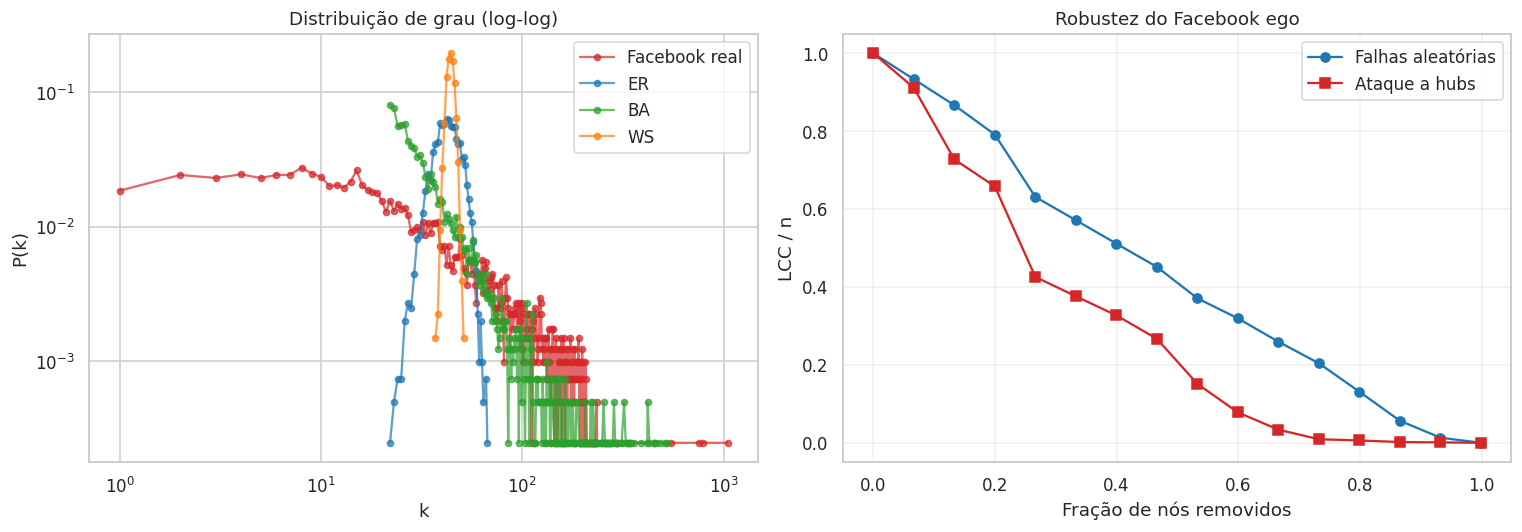


Top 3 vértices mais importantes (rank combinado):
      degree  betweenness  closeness  pagerank  rank_medio
107   0.2588       0.4823     0.4597    0.0069        1.25
1684  0.1961       0.3507     0.3936    0.0064        3.00
1912  0.1870       0.2199     0.3509    0.0039       10.00


In [7]:
# Comparação visual

# distribuição de grau log-log
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for name, G, c in [("Facebook real", G_real, "tab:red"),
                   ("ER", G_er, "tab:blue"),
                   ("BA", G_ba, "tab:green"),
                   ("WS", G_ws, "tab:orange")]:
    seq = np.array([d for _, d in G.degree()])
    vals, counts = np.unique(seq, return_counts=True)
    mask = vals > 0
    ax.loglog(vals[mask], counts[mask]/counts.sum(), "o-",
              label=name, color=c, alpha=0.7, ms=4)
ax.set_xlabel("k"); ax.set_ylabel("P(k)")
ax.set_title("Distribuição de grau (log-log)"); ax.legend()

# Sigma small-world
sigma = (real_m["clustering_avg"]/er_m["clustering_avg"]) / \
        (real_m["avg_shortest_path"]/er_m["avg_shortest_path"])
print(f"σ small-world = {sigma:.2f}   (>>1 ⇒ small-world)")
print(f"C(real)/C(ER) = {real_m['clustering_avg']/er_m['clustering_avg']:.2f}")
print(f"L(real)/L(ER) = {real_m['avg_shortest_path']/er_m['avg_shortest_path']:.2f}")

# aleatória vs ataque a hubs
def robustness(G, mode, steps=15):
    n0 = G.number_of_nodes()
    if mode == "rand":
        order = list(G.nodes()); np.random.default_rng(0).shuffle(order)
    else:
        order = [v for v,_ in sorted(G.degree(), key=lambda x: -x[1])]
    fracs, lcc_sizes = [], []
    for i in range(0, n0, max(1, n0//steps)):
        H = G.copy(); H.remove_nodes_from(order[:i])
        lcc = max(nx.connected_components(H), key=len) if H.number_of_edges() else set()
        fracs.append(i/n0); lcc_sizes.append(len(lcc)/n0)
    return fracs, lcc_sizes

print("\nSimulando robustez...")
xr, yr = robustness(G_real, "rand")
xt, yt = robustness(G_real, "targeted")

ax = axes[1]
ax.plot(xr, yr, "o-", label="Falhas aleatórias", color="tab:blue")
ax.plot(xt, yt, "s-", label="Ataque a hubs", color="tab:red")
ax.set_xlabel("Fração de nós removidos"); ax.set_ylabel("LCC / n")
ax.set_title("Robustez do Facebook ego"); ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout(); plt.savefig("parte2_comparacao.png", dpi=130, bbox_inches="tight"); plt.show()

# Top 3 por rank combinado
df_c = pd.DataFrame({
    "degree":      pd.Series(real_m["degree_c"]),
    "betweenness": pd.Series(real_m["betweenness"]),
    "closeness":   pd.Series(real_m["closeness"]),
    "pagerank":    pd.Series(real_m["pagerank"]),
})
df_c["rank_medio"] = df_c.rank(ascending=False).mean(axis=1)
top3 = df_c.sort_values("rank_medio").head(3)
print("\nTop 3 vértices mais importantes (rank combinado):")
print(top3.round(4))